# JEPA — embedding da DBO a partir de DQO e SST

O alvo continua sendo a DBO na entrada (`DBO-E`). O contexto é a mesma fila dos outros modelos: 10 leituras de DQO (`DQO-E`) e de SST (`SS-E`), até o dia estimado.

JEPA (Joint-Embedding Predictive Architecture) não treina prevendo a DBO em número. Um codificador transforma a fila em um vetor. Outro codificador transforma a DBO em um vetor do mesmo tamanho. Um preditor tenta acertar o vetor da DBO a partir do vetor da fila. A perda é a distância entre esses vetores. Uma penalidade de variância impede que todos os dias caiam no mesmo ponto. Só depois uma reta lê o vetor da fila e devolve a DBO.


In [1]:
from pathlib import Path
import sys
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.figsize": (6.2, 4.6),
    "axes.grid": True,
    "grid.color": "0.85",
    "grid.linewidth": 0.6,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "medium",
})

COR = "#1f4e79"
COR_REF = "#c45c26"
SEMENTE = 42
JANELA = 10
ENTRADAS = ["DQO-E", "SS-E"]
ALVO = "DBO-E"
PESO_VARIANCIA = 0.2
np.random.seed(SEMENTE)


def raiz_repositorio() -> Path:
    aqui = Path.cwd().resolve()
    for candidato in [aqui, *aqui.parents]:
        if (candidato / "data" / "water-treatment-plant" / "water-treatment.data").exists():
            return candidato
    raise FileNotFoundError("Repositório SoftSensor não encontrado.")


RAIZ = raiz_repositorio()
sys.path.insert(0, str(RAIZ / "modelo"))
from dados import carregar

FIGURAS = RAIZ / "docs" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)


## Série e janelas

O corte é o mesmo da RNN: os dias mais antigos treinam e os 20% mais recentes testam. Cada janela termina no dia cuja DBO se quer estimar e inclui as nove leituras anteriores disponíveis.


In [2]:
bruto = carregar()
tabela = (
    bruto.dropna(subset=[ALVO, *ENTRADAS])
    .loc[:, ["data", ALVO, *ENTRADAS]]
    .sort_values("data")
    .reset_index(drop=True)
)


def montar_janelas(serie, tamanho, inicio, fim):
    dqo = serie["DQO-E"].to_numpy(dtype=float)
    sst = serie["SS-E"].to_numpy(dtype=float)
    dbo = serie[ALVO].to_numpy(dtype=float)
    datas = serie["data"].to_numpy()
    xs, ys, fins = [], [], []
    for t in range(max(inicio, tamanho - 1), fim):
        a = t - tamanho + 1
        xs.append(np.column_stack([dqo[a:t + 1], sst[a:t + 1]]))
        ys.append(dbo[t])
        fins.append(datas[t])
    return np.stack(xs), np.asarray(ys, dtype=float), np.asarray(fins)


corte = int(len(tabela) * 0.8)
X_treino, y_treino, data_treino = montar_janelas(tabela, JANELA, 0, corte)
X_teste, y_teste, data_teste = montar_janelas(tabela, JANELA, corte, len(tabela))
print(f"dias completos: {len(tabela)}")
print(f"janelas de treino: {len(X_treino)}")
print(f"janelas de teste: {len(X_teste)}")
print(f"formato da fila: {X_treino.shape[1:]}")


dias completos: 498
janelas de treino: 389
janelas de teste: 100
formato da fila: (10, 2)


## Arquitetura

O codificador da fila achata as 10 leituras e passa por uma camada oculta com tangente hiperbólica. O codificador da DBO faz o mesmo a partir de um único número. O preditor liga os dois vetores. Os três têm a largura e a dimensão escolhidas na validação cruzada temporal, pelo MAE da reta de leitura no conjunto de validação.


In [3]:
def xavier(rng, entrada, saida):
    limite = np.sqrt(6 / (entrada + saida))
    return rng.uniform(-limite, limite, size=(entrada, saida))


def iniciar(largura, dimensao, semente):
    rng = np.random.default_rng(semente)
    entrada = JANELA * 2
    return {
        "Ex_W1": xavier(rng, entrada, largura),
        "Ex_b1": np.zeros(largura),
        "Ex_W2": xavier(rng, largura, dimensao),
        "Ex_b2": np.zeros(dimensao),
        "Ey_W1": xavier(rng, 1, largura),
        "Ey_b1": np.zeros(largura),
        "Ey_W2": xavier(rng, largura, dimensao),
        "Ey_b2": np.zeros(dimensao),
        "P_W1": xavier(rng, dimensao, largura),
        "P_b1": np.zeros(largura),
        "P_W2": xavier(rng, largura, dimensao),
        "P_b2": np.zeros(dimensao),
    }


def mlp(X, W1, b1, W2, b2):
    H = np.tanh(X @ W1 + b1)
    return H @ W2 + b2, H


def voltar_mlp(X, H, dZ, W1, W2):
    n = len(X)
    dW2 = H.T @ dZ / n
    db2 = dZ.sum(axis=0) / n
    d_pre = (dZ @ W2.T) * (1 - H ** 2)
    dW1 = X.T @ d_pre / n
    db1 = d_pre.sum(axis=0) / n
    return dW1, db1, dW2, db2, d_pre @ W1.T


def grad_variancia(Z, gamma=1.0):
    n, dim = Z.shape
    centro = Z - Z.mean(axis=0, keepdims=True)
    std = np.sqrt(np.mean(centro ** 2, axis=0) + 1e-4)
    ativo = (std < gamma).astype(float)
    dZ = -(ativo * centro / (n * std)) / dim
    return float(np.mean(np.maximum(0.0, gamma - std))), dZ


def codificar(X, y_padrao, params):
    plano = X.reshape(len(X), -1)
    zx, hx = mlp(plano, params["Ex_W1"], params["Ex_b1"], params["Ex_W2"], params["Ex_b2"])
    zy, hy = mlp(y_padrao.reshape(-1, 1), params["Ey_W1"], params["Ey_b1"], params["Ey_W2"], params["Ey_b2"])
    zh, hp = mlp(zx, params["P_W1"], params["P_b1"], params["P_W2"], params["P_b2"])
    return zx, hx, zy, hy, zh, hp


def gradientes(X, y_padrao, params):
    n = len(X)
    plano = X.reshape(n, -1)
    zx, hx, zy, hy, zh, hp = codificar(X, y_padrao, params)
    diff = zh - zy
    d_zh = 2 * diff / n
    d_zy = -2 * diff / n
    var_x, d_zx = grad_variancia(zx)
    var_y, d_zy_var = grad_variancia(zy)
    d_zy = d_zy + PESO_VARIANCIA * d_zy_var
    dP_W1, dP_b1, dP_W2, dP_b2, d_zx_pred = voltar_mlp(
        zx, hp, d_zh, params["P_W1"], params["P_W2"]
    )
    d_zx = d_zx_pred + PESO_VARIANCIA * d_zx
    dEx_W1, dEx_b1, dEx_W2, dEx_b2, _ = voltar_mlp(
        plano, hx, d_zx, params["Ex_W1"], params["Ex_W2"]
    )
    dEy_W1, dEy_b1, dEy_W2, dEy_b2, _ = voltar_mlp(
        y_padrao.reshape(-1, 1), hy, d_zy, params["Ey_W1"], params["Ey_W2"]
    )
    grads = {
        "Ex_W1": dEx_W1, "Ex_b1": dEx_b1, "Ex_W2": dEx_W2, "Ex_b2": dEx_b2,
        "Ey_W1": dEy_W1, "Ey_b1": dEy_b1, "Ey_W2": dEy_W2, "Ey_b2": dEy_b2,
        "P_W1": dP_W1, "P_b1": dP_b1, "P_W2": dP_W2, "P_b2": dP_b2,
    }
    norma = np.sqrt(sum(np.sum(g * g) for g in grads.values()))
    if norma > 1:
        for nome in grads:
            grads[nome] *= 1 / norma
    perda = float(np.mean(diff ** 2) + PESO_VARIANCIA * (var_x + var_y))
    return perda, grads, zx


def passo_adam(params, grads, momento, velocidade, t, taxa):
    t += 1
    for nome in params:
        momento[nome] = 0.9 * momento[nome] + 0.1 * grads[nome]
        velocidade[nome] = 0.999 * velocidade[nome] + 0.001 * grads[nome] ** 2
        m = momento[nome] / (1 - 0.9 ** t)
        v = velocidade[nome] / (1 - 0.999 ** t)
        params[nome] = params[nome] - taxa * m / (np.sqrt(v) + 1e-8)
    return t


def representar(X, sx, params):
    Xn = sx.transform(X.reshape(-1, 2)).reshape(X.shape)
    zx, _, _, _, _, _ = codificar(Xn, np.zeros(len(X)), params)
    return zx


def ajustar(X_tr, y_tr, X_va, y_va, largura, dimensao, taxa, semente, epocas=100, paciencia=12):
    sx = StandardScaler().fit(X_tr.reshape(-1, 2))
    sy = StandardScaler().fit(y_tr.reshape(-1, 1))
    Xtr = sx.transform(X_tr.reshape(-1, 2)).reshape(X_tr.shape)
    ytr = sy.transform(y_tr.reshape(-1, 1)).ravel()
    Xva = sx.transform(X_va.reshape(-1, 2)).reshape(X_va.shape)
    yva = sy.transform(y_va.reshape(-1, 1)).ravel()
    params = iniciar(largura, dimensao, semente)
    momento = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    velocidade = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    rng = np.random.default_rng(semente)
    melhor = copy.deepcopy(params)
    melhor_mae = np.inf
    melhor_epoca = 0
    espera = 0
    t = 0
    for epoca in range(1, epocas + 1):
        ordem = rng.permutation(len(Xtr))
        for inicio in range(0, len(Xtr), 64):
            idx = ordem[inicio:inicio + 64]
            _, grads, _ = gradientes(Xtr[idx], ytr[idx], params)
            t = passo_adam(params, grads, momento, velocidade, t, taxa)
        _, _, zx_tr = gradientes(Xtr, ytr, params)
        zx_va = representar(X_va, sx, params)
        leitura = LinearRegression().fit(zx_tr, y_tr)
        mae = mean_absolute_error(y_va, leitura.predict(zx_va))
        if mae < melhor_mae - 1e-4:
            melhor_mae = mae
            melhor_epoca = epoca
            melhor = copy.deepcopy(params)
            espera = 0
        else:
            espera += 1
            if espera >= paciencia:
                break
    return melhor, sx, float(melhor_mae), int(melhor_epoca)


grade = []
partes = TimeSeriesSplit(n_splits=5)
for largura in (16, 32):
    for dimensao in (8, 16):
        for taxa in (1e-3, 1e-2):
            maes, epocas = [], []
            for i, (tr, va) in enumerate(partes.split(X_treino), start=1):
                _, _, mae, epoca = ajustar(
                    X_treino[tr], y_treino[tr], X_treino[va], y_treino[va],
                    largura, dimensao, taxa, SEMENTE + i,
                )
                maes.append(mae)
                epocas.append(epoca)
            grade.append({
                "largura": largura,
                "dimensao": dimensao,
                "taxa": taxa,
                "MAE": float(np.mean(maes)),
                "desvio": float(np.std(maes)),
                "epocas": int(np.median(epocas)),
            })
            print(
                f"largura {largura:2d}  dim {dimensao:2d}  taxa {taxa:.0e}  "
                f"MAE {np.mean(maes):.2f} ± {np.std(maes):.2f}"
            )

ranking = pd.DataFrame(grade).sort_values("MAE").reset_index(drop=True)
escolha = ranking.iloc[0]
print("escolha:", escolha.to_dict())


largura 16  dim  8  taxa 1e-03  MAE 50.60 ± 8.78


largura 16  dim  8  taxa 1e-02  MAE 49.41 ± 8.84


largura 16  dim 16  taxa 1e-03  MAE 47.93 ± 7.56


largura 16  dim 16  taxa 1e-02  MAE 47.30 ± 6.87


largura 32  dim  8  taxa 1e-03  MAE 47.99 ± 5.62


largura 32  dim  8  taxa 1e-02  MAE 46.29 ± 6.05


largura 32  dim 16  taxa 1e-03  MAE 50.00 ± 8.31


largura 32  dim 16  taxa 1e-02  MAE 48.85 ± 6.78
escolha: {'largura': 32.0, 'dimensao': 8.0, 'taxa': 0.01, 'MAE': 46.28760166968671, 'desvio': 6.048199215119462, 'epocas': 1.0}


In [4]:
visao = ranking.copy()
visao["taxa"] = visao["taxa"].map(lambda valor: f"{valor:.0e}")
visao["MAE"] = visao["MAE"].map(lambda valor: f"{valor:.2f}")
visao["desvio"] = visao["desvio"].map(lambda valor: f"{valor:.2f}")
visao


,largura,dimensao,taxa,MAE,desvio,epocas
0,32,8,1e-02,46.29,6.05,1
1,16,16,1e-02,47.30,6.87,2
2,16,16,1e-03,47.93,7.56,16
3,32,8,1e-03,47.99,5.62,4
4,32,16,1e-02,48.85,6.78,5
5,16,8,1e-02,49.41,8.84,10
6,32,16,1e-03,50.00,8.31,1
7,16,8,1e-03,50.60,8.78,13


## Teste

O modelo final treina em todas as janelas de treino pelo número mediano de épocas da validação. A reta de leitura é ajustada só nessas janelas. As referências usam o mesmo corte da RNN: média do treino, reta da leitura mais recente e reta das 10 leituras.


In [5]:
def avaliar(y_obs, y_prev):
    return {
        "MAE": mean_absolute_error(y_obs, y_prev),
        "RMSE": float(np.sqrt(mean_squared_error(y_obs, y_prev))),
        "R2": r2_score(y_obs, y_prev),
    }


def ajustar_final(X_tr, y_tr, largura, dimensao, taxa, semente, epocas):
    sx = StandardScaler().fit(X_tr.reshape(-1, 2))
    sy = StandardScaler().fit(y_tr.reshape(-1, 1))
    Xtr = sx.transform(X_tr.reshape(-1, 2)).reshape(X_tr.shape)
    ytr = sy.transform(y_tr.reshape(-1, 1)).ravel()
    params = iniciar(largura, dimensao, semente)
    momento = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    velocidade = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    rng = np.random.default_rng(semente)
    t = 0
    for _ in range(epocas):
        ordem = rng.permutation(len(Xtr))
        for inicio in range(0, len(Xtr), 64):
            idx = ordem[inicio:inicio + 64]
            _, grads, _ = gradientes(Xtr[idx], ytr[idx], params)
            t = passo_adam(params, grads, momento, velocidade, t, taxa)
    return params, sx


largura = int(escolha["largura"])
dimensao = int(escolha["dimensao"])
taxa = float(escolha["taxa"])
epocas_finais = max(int(escolha["epocas"]), 1)
modelo, sx = ajustar_final(X_treino, y_treino, largura, dimensao, taxa, SEMENTE, epocas_finais)
z_treino = representar(X_treino, sx, modelo)
z_teste = representar(X_teste, sx, modelo)
leitura = LinearRegression().fit(z_treino, y_treino)
y_jepa = leitura.predict(z_teste)

y_media = np.full(len(y_teste), float(y_treino.mean()))
linear_atual = LinearRegression().fit(X_treino[:, -1, :], y_treino)
y_linear_atual = linear_atual.predict(X_teste[:, -1, :])
linear_fila = LinearRegression().fit(X_treino.reshape(len(X_treino), -1), y_treino)
y_linear_fila = linear_fila.predict(X_teste.reshape(len(X_teste), -1))

resultados = pd.DataFrame(
    [
        avaliar(y_teste, y_media),
        avaliar(y_teste, y_linear_atual),
        avaliar(y_teste, y_linear_fila),
        avaliar(y_teste, y_jepa),
    ],
    index=["Média do treino", "Linear da leitura atual", "Linear das 10 leituras", "JEPA"],
)
zx_fim, _, zy_fim, _, zh_fim, _ = codificar(
    sx.transform(X_treino.reshape(-1, 2)).reshape(X_treino.shape),
    StandardScaler().fit(y_treino.reshape(-1, 1)).transform(y_treino.reshape(-1, 1)).ravel(),
    modelo,
)
print(f"épocas do ajuste final: {epocas_finais}")
print(f"parâmetros: {sum(np.size(valor) for valor in modelo.values())}")
print(f"desvio médio do embedding da fila: {zx_fim.std(axis=0).mean():.3f}")
print(f"desvio médio do embedding da DBO: {zy_fim.std(axis=0).mean():.3f}")
print(f"desvio médio do embedding previsto: {zh_fim.std(axis=0).mean():.3f}")
resultados.round(2)


épocas do ajuste final: 1
parâmetros: 1816
desvio médio do embedding da fila: 0.528
desvio médio do embedding da DBO: 0.061
desvio médio do embedding previsto: 0.119


,MAE,RMSE,R2
Média do treino,40.88,48.15,-0.73
Linear da leitura atual,33.13,40.75,-0.24
Linear das 10 leituras,34.08,42.83,-0.37
JEPA,32.78,41.39,-0.28


In [6]:
residuo = y_teste - y_jepa
erro_abs = np.abs(residuo)
print(f"previsão mínima no teste: {y_jepa.min():.2f}")
print(f"previsão máxima no teste: {y_jepa.max():.2f}")
print(f"DBO mínima no teste: {y_teste.min():.2f}")
print(f"DBO máxima no teste: {y_teste.max():.2f}")
print(f"resíduo médio no teste: {residuo.mean():.2f}")
print(f"erro absoluto mediano: {np.median(erro_abs):.2f}")
print(f"erro absoluto no percentil 90: {np.quantile(erro_abs, 0.9):.2f}")
print(f"fração com |erro| até 30: {(erro_abs <= 30).mean():.2f}")
print(f"fração com |erro| até 50: {(erro_abs <= 50).mean():.2f}")
print(f"erro quadrático médio entre o embedding previsto e o da DBO: {np.mean((zh_fim - zy_fim) ** 2):.4f}")
correlacoes = [
    np.corrcoef(zh_fim[:, eixo], zy_fim[:, eixo])[0, 1]
    for eixo in range(zh_fim.shape[1])
]
print(f"correlação média por eixo do embedding, no treino: {np.nanmean(correlacoes):.3f}")


previsão mínima no teste: 122.15
previsão máxima no teste: 303.87
DBO mínima no teste: 84.00
DBO máxima no teste: 277.00
resíduo médio no teste: -22.06
erro absoluto mediano: 27.42
erro absoluto no percentil 90: 70.11
fração com |erro| até 30: 0.55
fração com |erro| até 50: 0.76
erro quadrático médio entre o embedding previsto e o da DBO: 0.0220
correlação média por eixo do embedding, no treino: -0.023


## Gráficos do teste

A reta laranja marca a previsão igual à observação. O terceiro gráfico é o embedding da fila no teste, reduzido a duas componentes: a cor é a DBO observada.


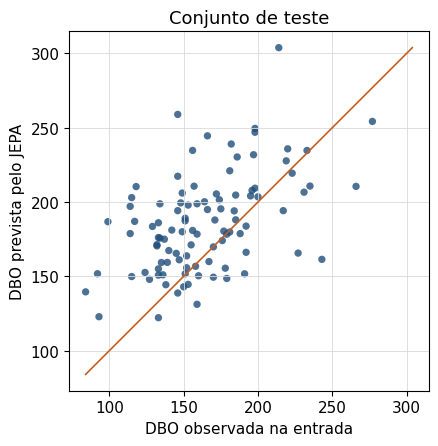

In [7]:
def salvar(fig, nome):
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nome}.pdf")
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150)
    plt.show()


fig, ax = plt.subplots()
ax.scatter(y_teste, y_jepa, s=28, alpha=0.8, c=COR, edgecolors="none")
limites = [min(y_teste.min(), y_jepa.min()), max(y_teste.max(), y_jepa.max())]
ax.plot(limites, limites, color=COR_REF, linewidth=1.2)
ax.set_xlabel("DBO observada na entrada")
ax.set_ylabel("DBO prevista pelo JEPA")
ax.set_title("Conjunto de teste")
ax.set_aspect("equal", adjustable="box")
salvar(fig, "jepa_observado_previsto")


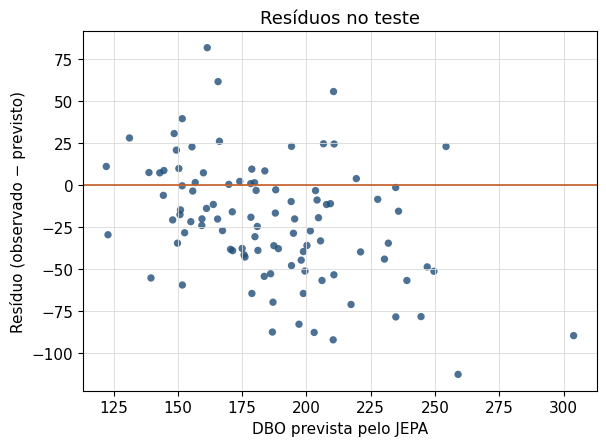

In [8]:
fig, ax = plt.subplots()
ax.scatter(y_jepa, residuo, s=28, alpha=0.8, c=COR, edgecolors="none")
ax.axhline(0, color=COR_REF, linewidth=1.2)
ax.set_xlabel("DBO prevista pelo JEPA")
ax.set_ylabel("Resíduo (observado − previsto)")
ax.set_title("Resíduos no teste")
salvar(fig, "jepa_residuos")


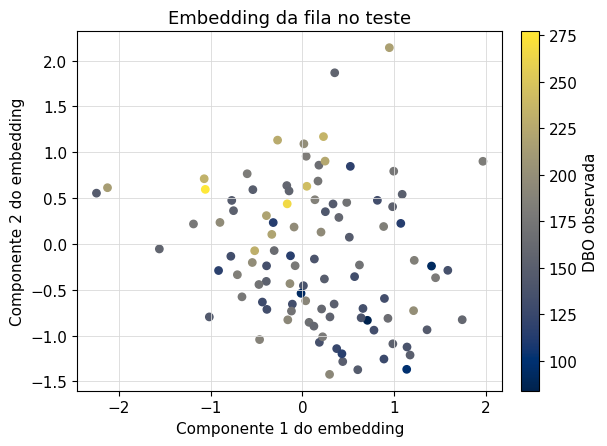

In [9]:
pca = PCA(n_components=2).fit(z_treino)
plano = pca.transform(z_teste)
fig, ax = plt.subplots()
pontos = ax.scatter(plano[:, 0], plano[:, 1], c=y_teste, cmap="cividis", s=28)
ax.set_xlabel("Componente 1 do embedding")
ax.set_ylabel("Componente 2 do embedding")
ax.set_title("Embedding da fila no teste")
fig.colorbar(pontos, ax=ax, fraction=0.046, pad=0.04).set_label("DBO observada")
salvar(fig, "jepa_embedding")


## Leitura

No mesmo corte da RNN, o JEPA tem MAE 32,78, RMSE 41,39 e R² −0,28. A reta da leitura atual tem MAE 33,13 e RMSE 40,75. A RNN, neste corte, tem MAE 32,00 e RMSE 40,68. A validação escolheu largura 32, embedding de 8 e taxa 0,01, e parou em 1 época. As outras configurações ficam entre 46,29 e 50,60 de MAE na validação.

O embedding previsto não acompanha o da DBO: a correlação média por eixo, no treino, é −0,02, e o desvio do vetor da DBO fica em 0,061. A reta de leitura, sobre o vetor da fila, é quem produz o número. O resíduo médio no teste é −22,06, o mesmo deslocamento de nível do período final.

A análise escrita está em docs/jepa_dbo_entrada.pdf.
